# Monte Carlo Options Hedging & Risk Simulator

**Educational project using synthetic data.** Compares the risk–cost trade-off between daily, 5-day, and inception-only hedging of a short European call option. Uses 10,000 simulated price paths and three realized volatility scenarios. No real backtest, prediction of market returns or proven trading alpha.

### Before running
Run the next cell to install the required packages **only if needed**:

```python
%pip install numpy pandas scipy matplotlib
```

Then click **Kernel → Restart Kernel**, if installation occurred, and **Run → Run All Cells**. The code saves a results CSV and two figures into folders next to this notebook.

- Assumed stock price = strike = $100
- Quote/hedge volatility = 25%, realized volatility = 20%, 25%, or 30%
- Time to expiry = 30 trading days; zero interest rate, no dividends
- One **synthetic** call on **one share** (not a standard 100-share contract)
- Cost scenarios = 0 or 10 basis points per stock trade
- Same simulated random shocks used to compare policies


Initial Black-Scholes call premium: $3.4401
Initial delta: 0.5172 shares per call

25% realized volatility and 10 bps trading costs:
 hedge_every_days  mean_pnl  std_pnl  pnl_5th_percentile  worst_5pct_average  probability_of_loss
                1   -0.2778   0.5502             -1.2123             -1.5941               0.7105
                5   -0.1710   1.1635             -2.1489             -2.9054               0.5552
               30   -0.1197   2.6069             -5.0959             -6.8051               0.4425


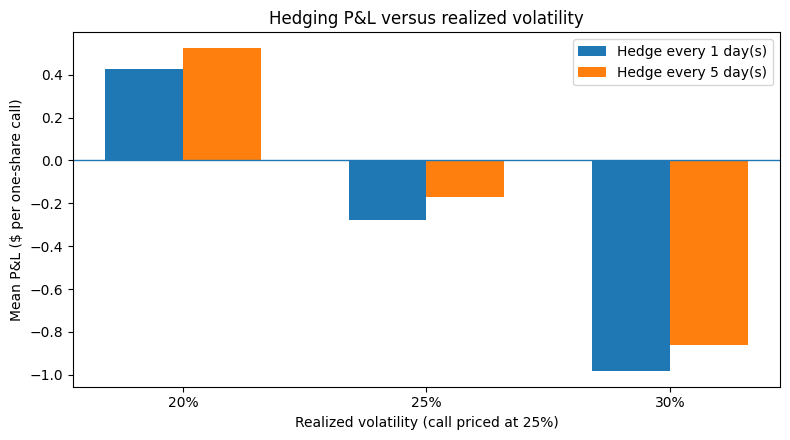

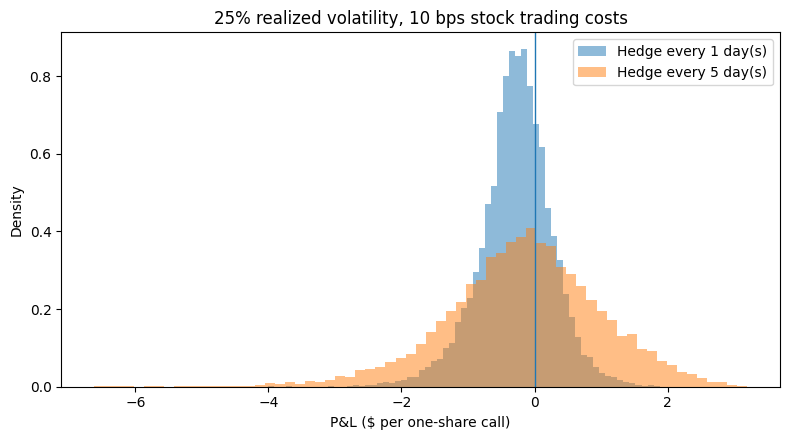


Finished. Files saved to results/ and figures/.
Educational simulation only; no real data or proven trading alpha.


In [1]:
# Monte Carlo Options Hedging & Risk Simulator
# Educational simulation using SYNTHETIC prices (not real trading performance).
# All P&L is USD per one European call on ONE share.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr  # Standard normal cumulative distribution function

# ---------- 1. Settings ----------
S0 = 100.0                  # Stock price today ($)
K = 100.0                   # Call strike price ($)
IV = 0.25                   # Annual volatility used to price/hedge the call
DAYS = 30                   # Trading days until expiration
TRADING_DAYS = 252
N_PATHS = 10_000
SEED = 2027
REALIZED_VOLS = [0.20, 0.25, 0.30]
HEDGE_FREQUENCIES = [1, 5, 30]   # Daily, every 5 days, inception only
COSTS_BPS = [0, 10]             # Stock trading costs in basis points

# Works inside Jupyter without any companion .py files.
Path('results').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

# ---------- 2. Black-Scholes call price and delta ----------
def call_price_and_delta(spot, years_left, vol=IV):
    """European call, zero interest rate and no dividends."""
    s = np.asarray(spot, dtype=float)
    if years_left <= 0:
        return np.maximum(s - K, 0), (s > K).astype(float)

    denominator = vol * np.sqrt(years_left)
    d1 = (np.log(s / K) + 0.5 * vol**2 * years_left) / denominator
    d2 = d1 - denominator
    call_price = s * ndtr(d1) - K * ndtr(d2)
    delta = ndtr(d1)
    return call_price, delta

# ---------- 3. Simulate stock prices ----------
def simulate_stock_paths(realized_vol, shocks):
    """Geometric Brownian motion with zero expected stock-price return."""
    dt = 1.0 / TRADING_DAYS
    log_returns = (
        -0.5 * realized_vol**2 * dt
        + realized_vol * np.sqrt(dt) * shocks
    )
    stock_prices = S0 * np.exp(np.cumsum(log_returns, axis=1))
    return np.column_stack([np.full(N_PATHS, S0), stock_prices])

# ---------- 4. Simulate short call + stock delta hedge ----------
def hedged_call_pnl(stock_paths, rebalance_every, cost_bps):
    """Sell one call, buy delta shares, rebalance, then settle at maturity.

    Fees apply when buying the initial hedge, rebalancing, and liquidating.
    """
    premium, starting_delta = call_price_and_delta(S0, DAYS / TRADING_DAYS)
    fee = cost_bps / 10_000

    shares = np.full(N_PATHS, float(starting_delta))
    cash = np.full(
        N_PATHS,
        float(premium - starting_delta * S0 - abs(starting_delta) * S0 * fee)
    )

    for day in range(1, DAYS):
        if day % rebalance_every != 0:
            continue
        today_price = stock_paths[:, day]
        time_left = (DAYS - day) / TRADING_DAYS
        _, desired_shares = call_price_and_delta(today_price, time_left)
        shares_to_trade = desired_shares - shares
        transaction_fee = np.abs(shares_to_trade) * today_price * fee
        cash -= shares_to_trade * today_price + transaction_fee
        shares = desired_shares

    final_price = stock_paths[:, -1]
    call_payoff = np.maximum(final_price - K, 0)
    liquidation_fee = np.abs(shares) * final_price * fee
    pnl = cash + shares * final_price - call_payoff - liquidation_fee
    return pnl

# ---------- 5. Metrics ----------
def summarize(pnl):
    fifth_percentile = np.percentile(pnl, 5)
    return {
        'mean_pnl': float(np.mean(pnl)),
        'std_pnl': float(np.std(pnl)),
        'pnl_5th_percentile': float(fifth_percentile),
        'worst_5pct_average': float(np.mean(pnl[pnl <= fifth_percentile])),
        'probability_of_loss': float(np.mean(pnl < 0)),
    }

# ---------- 6. Run all 18 scenarios ----------
rng = np.random.default_rng(SEED)
random_shocks = rng.standard_normal((N_PATHS, DAYS))
rows = []
base_pnls = {}

for realized_vol in REALIZED_VOLS:
    paths = simulate_stock_paths(realized_vol, random_shocks)
    for frequency in HEDGE_FREQUENCIES:
        for cost in COSTS_BPS:
            pnl = hedged_call_pnl(paths, frequency, cost)
            rows.append({
                'realized_vol': realized_vol,
                'hedge_every_days': frequency,
                'cost_bps': cost,
                **summarize(pnl),
            })
            if realized_vol == 0.25 and cost == 10:
                base_pnls[frequency] = pnl

results = pd.DataFrame(rows)
results.to_csv('results/simulation_summary.csv', index=False)

# ---------- 7. Display initial premium and baseline result ----------
premium, initial_delta = call_price_and_delta(S0, DAYS / TRADING_DAYS)
print(f'Initial Black-Scholes call premium: ${float(premium):.4f}')
print(f'Initial delta: {float(initial_delta):.4f} shares per call')
print('\n25% realized volatility and 10 bps trading costs:')
base = results[(results.realized_vol == 0.25) & (results.cost_bps == 10)]
print(base[['hedge_every_days', 'mean_pnl', 'std_pnl',
            'pnl_5th_percentile', 'worst_5pct_average',
            'probability_of_loss']].round(4).to_string(index=False))

# ---------- 8. Chart: mean P&L versus realized volatility ----------
fig, ax = plt.subplots(figsize=(8, 4.5))
locations = np.arange(len(REALIZED_VOLS))
for i, freq in enumerate([1, 5]):
    subset = results[(results.hedge_every_days == freq) &
                     (results.cost_bps == 10)].sort_values('realized_vol')
    ax.bar(locations + (i - 0.5) * 0.32, subset.mean_pnl,
           width=0.32, label=f'Hedge every {freq} day(s)')
ax.set_xticks(locations)
ax.set_xticklabels(['20%', '25%', '30%'])
ax.axhline(0, linewidth=1)
ax.set_xlabel('Realized volatility (call priced at 25%)')
ax.set_ylabel('Mean P&L ($ per one-share call)')
ax.set_title('Hedging P&L versus realized volatility')
ax.legend()
fig.tight_layout()
fig.savefig('figures/volatility_sensitivity.png', dpi=160)
plt.show()

# ---------- 9. Chart: baseline P&L distributions ----------
fig, ax = plt.subplots(figsize=(8, 4.5))
for freq in [1, 5]:
    ax.hist(base_pnls[freq], bins=65, density=True, alpha=0.5,
            label=f'Hedge every {freq} day(s)')
ax.axvline(0, linewidth=1)
ax.set_xlabel('P&L ($ per one-share call)')
ax.set_ylabel('Density')
ax.set_title('25% realized volatility, 10 bps stock trading costs')
ax.legend()
fig.tight_layout()
fig.savefig('figures/pnl_distribution.png', dpi=160)
plt.show()

# ---------- 10. Basic verification ----------
# Increasing transaction costs must not improve pathwise profits.
verify_paths = simulate_stock_paths(0.25, random_shocks)
for freq in HEDGE_FREQUENCIES:
    without_fees = hedged_call_pnl(verify_paths, freq, 0)
    with_fees = hedged_call_pnl(verify_paths, freq, 10)
    assert np.all(with_fees <= without_fees + 1e-9)

print('\nFinished. Files saved to results/ and figures/.')
print('Educational simulation only; no real data or proven trading alpha.')


## What the output means

- **`mean_pnl`**: average of ending profit/loss across simulated paths.
- **`std_pnl`**: dispersion of simulated profits/losses; smaller means less variation, not more profit.
- **`pnl_5th_percentile`**: loss-tail cutoff; 5% of simulated outcomes fall below it.
- **`worst_5pct_average`**: average P&L among the worst 5% of paths.
- **`probability_of_loss`**: share of paths where ending P&L was negative.

### Three experiments to understand the simulator

1. Change `COSTS_BPS = [0, 10]` to `[0, 10, 20]`, rerun and compare average P&L for daily vs 5-day hedging.
2. Change `REALIZED_VOLS` to `[0.15, 0.25, 0.35]` and explain what happens when actual volatility differs from the priced 25%.
3. In 2–3 sentences, explain **why more frequent hedging can reduce risk yet worsen average P&L after fees**.

**Limitations:** Constant-volatility geometric Brownian motion, European call, no jumps, no realistic options bid–ask spread or order execution, no margin/funding model. If AI helped write the code, describe your real contribution and ability to explain/modify the model accurately in applications and interviews.
